In [1]:
!pip install rasterio matplotlib numpy

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.4 MB ? eta -:--:--
   -- ------------------------------------- 1.6/31.4 MB 5.3 MB/s eta 0:00:06
   --- ------------------------------------ 2.4/31.4 MB 4.6 MB/s eta 0:00:07
   ---- ----------------------------------- 3.1/31.4 MB 4.4 MB/s eta 0:00:07
   ----- ---------------------------------- 3.9/31.4 MB 4.3 MB/s eta 0:00:07
   ------ --------------------------------- 4.7/31.4 MB 4.2 MB/s eta 0:00:07
   ------- -------------------------------- 5.8/31.4 MB 4.1 MB/s eta 0:00:07
   -------- ------------------------------- 6.6/31.4 MB 4.1 MB/s eta 0:00:07
   --------- ------------------------------ 7.3/31.4 MB 4.1 MB/s eta 0:00:06
   ---------- ----------------------------- 8.1/31.4 MB 4.1 MB/s eta 0:00:06
   ----------- ---------------------------- 8.9/31.4 MB 4.0 MB/s eta 0:00:06
   ---------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import os
import rasterio
import numpy as np

In [8]:
s1_folder = r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\S1Hand"
label_folder = r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\LabelHand"

image_name = "Bolivia_103757_S1Hand.tif"
label_name = "Bolivia_103757_LabelHand.tif"

image_path = os.path.join(s1_folder, image_name)
label_path = os.path.join(label_folder, label_name)

len(image_name)

25

In [11]:
### dataset info
with rasterio.open(image_path) as src:
    print("file:",image_name[0])
    print("width:",src.width)
    print("height:",src.height)
    print("no.of bands:",src.count)
    print("data type:",src.dtypes)
    
    
    image = src.read()
    print("Image shape:", image.shape)
    print("Minimum value:", image.min())
    print("Maximum value:", image.max())
    for i in range(src.count):
        print(f"Band {i+1}:")
        print("  Min:", image[i].min())
        print("  Max:", image[i].max())
        print("  Mean:", image[i].mean())

file: B
width: 512
height: 512
no.of bands: 2
data type: ('float32', 'float32')
Image shape: (2, 512, 512)
Minimum value: nan
Maximum value: nan
Band 1:
  Min: nan
  Max: nan
  Mean: nan
Band 2:
  Min: nan
  Max: nan
  Mean: nan


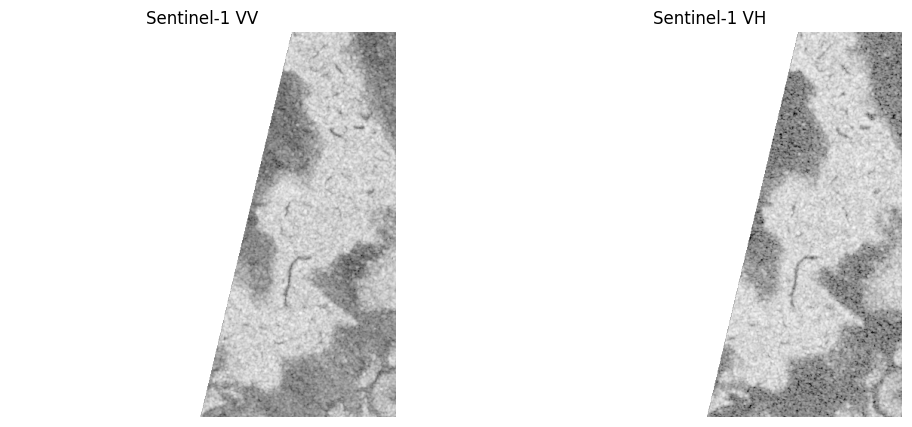

In [12]:
### vv and vh representation
import matplotlib.pyplot as plt

with rasterio.open(image_path) as src:
    vv = src.read(1)
    vh = src.read(2)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(vv, cmap="gray")
plt.title("Sentinel-1 VV")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vh, cmap="gray")
plt.title("Sentinel-1 VH")
plt.axis("off")

plt.show()

In [13]:
print("VV - valid pixels:", np.sum(np.isfinite(vv)))
print("VV - total pixels:", vv.size)

print("VH - valid pixels:", np.sum(np.isfinite(vh)))
print("VH - total pixels:", vh.size)

print("\nVV - NaN pixels:", np.sum(np.isnan(vv)))
print("VH - NaN pixels:", np.sum(np.isnan(vh)))

VV - valid pixels: 101623
VV - total pixels: 262144
VH - valid pixels: 101623
VH - total pixels: 262144

VV - NaN pixels: 160521
VH - NaN pixels: 160521


In [15]:
with rasterio.open(label_path) as src:
    label = src.read(1)

print("Label shape:", label.shape)
print("Label data type:", label.dtype)
print("Unique label values:", np.unique(label))

Label shape: (512, 512)
Label data type: int16
Unique label values: [-1  0  1]


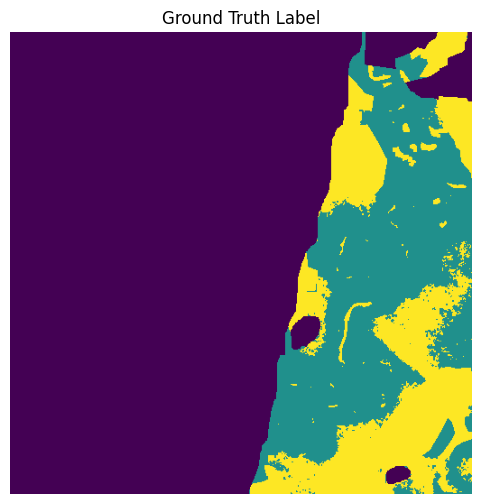

In [17]:
### Ground-Truth Label Inspection
plt.figure(figsize=(6, 6))

plt.imshow(label)
plt.title("Ground Truth Label")
plt.axis("off")

plt.show()

In [19]:
import os
print(os.path.abspath("major_project.ipynb"))

C:\Users\GNANA SRIHASA\major_project.ipynb
